# **Prophet**


This notebook is an extension of `01_EDA_e_Extracao.ipynb`, which contains the full exploratory data analysis of the IPCA series.

> **Prerequisite:** this notebook assumes that you have already run `01_EDA_e_Extracao.ipynb`. The data loading process is condensed below into a single cell for brevity, only the essential steps required by Prophet are kept here.

Here we focus exclusively on the Prophet model, both without and with exogenous variables.

## **Data loading**

In [1]:
import os
# REQUIRED: Must come before importing Prophet or cmdstanpy
os.environ["STAN_VERBOSE"] = "FALSE"


import pandas as pd
import requests

codigos = {
    'ipca': 433,
    'selic': 4189,
    'cambio': 3698,
    'igpm': 189
}

dfs = {}
for nome, codigo in codigos.items():
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json'
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    df_temp = pd.DataFrame(response.json())
    df_temp['data'] = pd.to_datetime(df_temp['data'], format='%d/%m/%Y')
    df_temp['valor'] = pd.to_numeric(df_temp['valor'], errors='coerce')
    df_temp = df_temp.rename(columns={'valor': nome})
    dfs[nome] = df_temp

print("Series loaded:")
for nome, df in dfs.items():
    print(f"{nome}: {df.shape[0]} records | {df['data'].min().date()} até {df['data'].max().date()}")

df_master = dfs['ipca'].copy()

for nome in ['selic', 'cambio', 'igpm']:
    df_master = df_master.merge(dfs[nome], on='data', how='inner')

Series loaded:
ipca: 561 records | 1980-01-01 até 2026-09-01
selic: 483 records | 1986-08-01 até 2026-10-01
cambio: 884 records | 1953-02-01 até 2026-09-01
igpm: 448 records | 1989-06-01 até 2026-09-01


## **Level 1**

In [2]:
# Filter for years after 2000
df_filtrado = df_master[df_master['data'] >= '2000-01-01'].reset_index(drop=True)

# Current year = The most recent year available in the data
ano_atual = df_filtrado['data'].max().year
inicio_ano_atual = pd.Timestamp(f'{ano_atual}-01-01')

df_train = df_filtrado[df_filtrado['data'] < inicio_ano_atual].reset_index(drop=True)
df_test  = df_filtrado[df_filtrado['data'] >= inicio_ano_atual].reset_index(drop=True)

print(f"Treino: {df_train.shape} | {df_train['data'].min().date()} → {df_train['data'].max().date()}")
print(f"Teste:  {df_test.shape} | {df_test['data'].min().date()} → {df_test['data'].max().date()}")


Treino: (312, 5) | 2000-01-01 → 2025-12-01
Teste:  (9, 5) | 2026-01-01 → 2026-09-01


Prophet requires two specific column names: 'ds' (datestamp) and 'y' (target variable).

In [3]:
from prophet import Prophet

df_proph = df_train[['data', 'ipca']].rename(columns={'data': 'ds', 'ipca': 'y'})

print(df_proph.shape)
print(df_proph.head())

(312, 2)
          ds     y
0 2000-01-01  0.62
1 2000-02-01  0.13
2 2000-03-01  0.22
3 2000-04-01  0.42
4 2000-05-01  0.01


We instantiate the model with additive seasonality, given the presence of deflation
in the historical series. Daily and weekly seasonalities are disabled since the data
is monthly.

In [4]:
model_proph = Prophet(
    seasonality_mode = 'additive',
    yearly_seasonality = True,
    weekly_seasonality = False,
    daily_seasonality = False,
    interval_width=0.80
)

model_proph.fit(df_proph)
print('Model fitted')

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
21:10:32 - cmdstanpy - INFO - Chain [1] start processing


21:10:32 - cmdstanpy - INFO - Chain [1] done processing


Model fitted


Since we want to forecast the future, we need to create a DataFrame containing
those future dates for Prophet to fill with predictions.

In [5]:

periods_auto = len(df_test)
futuro = model_proph.make_future_dataframe(periods=periods_auto, freq = 'MS')
print(futuro.tail())

            ds
316 2026-05-01
317 2026-06-01
318 2026-07-01
319 2026-08-01
320 2026-09-01


With the trained model, we apply .predict() to compute the expected inflation values.
We extract yhat (our main estimate) along with yhat_lower and yhat_upper, which define
the uncertainty interval at the 80% confidence level set during model instantiation.

In [6]:
forecast = model_proph.predict(futuro)
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

            ds      yhat  yhat_lower  yhat_upper
316 2026-05-01  0.288514   -0.188963    0.712590
317 2026-06-01  0.195470   -0.253538    0.641988
318 2026-07-01  0.255503   -0.184319    0.705053
319 2026-08-01  0.191854   -0.260149    0.628622
320 2026-09-01  0.309928   -0.141645    0.734874


We generate a comparative chart between the actual values and the model's predictions.

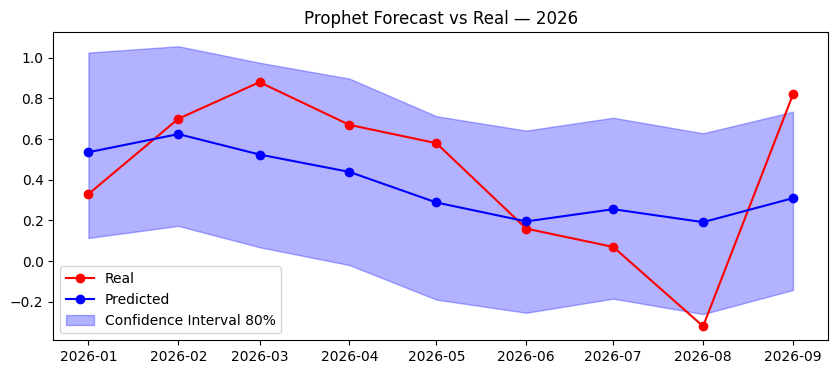

In [7]:
import matplotlib.pyplot as plt

forecast_2026 = forecast[forecast['ds'] >= '2026-01-01'][['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

plt.figure(figsize=(10, 4))
plt.plot(df_test['data'], df_test['ipca'], color='red', marker='o', label='Real')
plt.plot(forecast_2026['ds'], forecast_2026['yhat'], color='blue', marker='o', label='Predicted')
plt.fill_between(forecast_2026['ds'], forecast_2026['yhat_lower'], forecast_2026['yhat_upper'], alpha=0.3, color='blue', label='Confidence Interval 80%')
plt.title('Prophet Forecast vs Real — 2026')
plt.legend()
plt.show()

Since the IPCA series contains historically low values close to zero, including
deflationary months. Relative percentage metrics such as MAPE suffer severe
mathematical distortions. Therefore, MAE (Mean Absolute Error) is adopted as the
primary metric, measuring the real impact of errors in percentage points.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_real = df_test['ipca'].values
y_pred = forecast[forecast['ds'] >= '2026-01-01']['yhat'].values

mae = mean_absolute_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))

print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')

MAE: 0.2669
RMSE: 0.3110


## **LEVEL 2 - ADD REGRESSOR**

In Level 2, we incorporate exogenous variables into the model: SELIC interest rate,
USD/BRL exchange rate, and IGP-M. We maintain the same training cutoff and the same
additive configuration from Level 1. Note that the Prophet holidays feature is not
used here, since our variables are continuous time series rather than specific calendar
dates. The exogenous regressors are registered before fitting the model.

In [9]:
# Prepare the training dataset, including the regressors
df_train_reg = df_train[['data', 'ipca', 'selic', 'cambio', 'igpm']].copy()
df_train_reg = df_train_reg.rename(columns={'data': 'ds', 'ipca': 'y'})

# Initialize the new model (same base parameters as Level 1)
model_proph_reg = Prophet(
    seasonality_mode='additive',
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.80
)

# Add the exogenous variables
model_proph_reg.add_regressor('selic')
model_proph_reg.add_regressor('cambio')
model_proph_reg.add_regressor('igpm')

In [10]:
# Train the model
model_proph_reg.fit(df_train_reg)
print('Level 2 model trained with exogenous variables!')

21:10:33 - cmdstanpy - INFO - Chain [1] start processing


21:10:33 - cmdstanpy - INFO - Chain [1] done processing


Level 2 model trained with exogenous variables!


Unlike Level 1, Prophet now requires the future DataFrame to contain not only the
dates ('ds') but also the values of each registered regressor for the forecast
period. Since `df_filtrado` already contains the full post-2000 data, we use it directly, renaming the date column to 'ds'.

In [11]:
df_future_reg = df_filtrado[['data', 'selic', 'cambio', 'igpm']].copy()
df_future_reg = df_future_reg.rename(columns={'data': 'ds'})

In [12]:
# forecasting
forecast_reg = model_proph_reg.predict(df_future_reg)
print(forecast_reg[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

            ds      yhat  yhat_lower  yhat_upper
316 2026-05-01  0.611554    0.262156    0.964660
317 2026-06-01  0.170023   -0.197327    0.537325
318 2026-07-01  0.047181   -0.277855    0.405071
319 2026-08-01  0.202216   -0.126995    0.560638
320 2026-09-01  0.736402    0.382322    1.110484


In [13]:
# Evaluating performance for the test period only (2026)
forecast_reg_2026 = forecast_reg[forecast_reg['ds'] >= '2026-01-01']

In [14]:
y_real_reg = df_test['ipca'].values
y_pred_reg = forecast_reg_2026['yhat'].values

mae_reg = mean_absolute_error(y_real_reg, y_pred_reg)
rmse_reg = np.sqrt(mean_squared_error(y_real_reg, y_pred_reg))

print('-' * 30)
print('LEVEL 2 RESULTS (With Exogenous Variables):')
print(f'MAE: {mae_reg:.4f}')
print(f'RMSE: {rmse_reg:.4f}')


------------------------------
LEVEL 2 RESULTS (With Exogenous Variables):
MAE: 0.2206
RMSE: 0.2998


### **Visual Comparison — Level 1 vs Level 2 vs Real**


The chart below overlays both Prophet models against the actual 2026 IPCA values,
making the performance gap between the pure and the regressor-based model visually
explicit.

The chart reveals that Prophet with exogenous variables tends to perform
particularly well during months where macroeconomic conditions shift
significantly, capturing movements that the pure model misses.


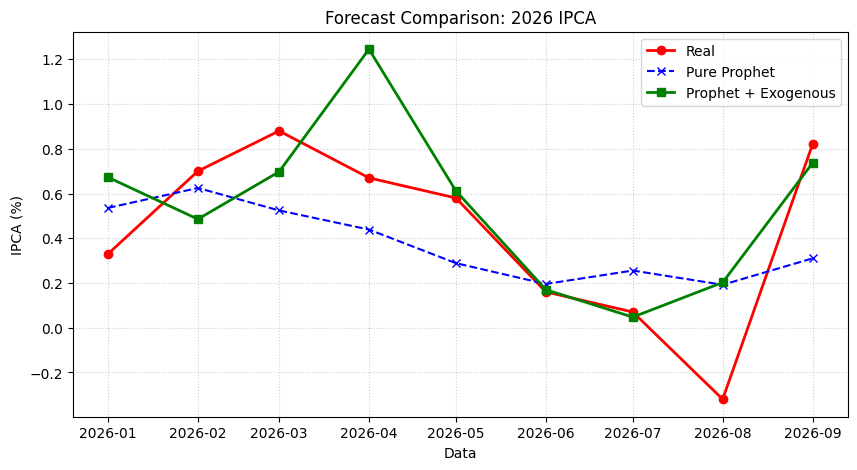

In [15]:
plt.figure(figsize=(10, 5))
# Real
plt.plot(df_test['data'], df_test['ipca'], color='red', marker='o', linewidth=2, label='Real')

# level 1
plt.plot(forecast_2026['ds'], forecast_2026['yhat'], color='blue', marker='x', linestyle='--', label='Pure Prophet')

# level 2
plt.plot(forecast_reg_2026['ds'], forecast_reg_2026['yhat'], color='green', marker='s', linewidth=2, label='Prophet + Exogenous')

plt.title('Forecast Comparison: 2026 IPCA')
plt.xlabel('Data')
plt.ylabel('IPCA (%)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### **Results — Level 2 vs Level 1**

Level 2 (Prophet + exogenous) clearly outperforms Level 1, both visually and in the holdout metrics. The chart above makes this evident: the Level 2 forecast tracks the actual IPCA trajectory much more closely, especially during months where macroeconomic conditions shift abruptly such as the reversal from deflation in August 2026 to a sharp uptick in September 2026.

The reason is simple: the exogenous variables give the model context that the seasonal pattern alone cannot provide. When SELIC, exchange rate, and IGP-M move, they carry information about where inflation is heading. Level 1 only sees the calendar; Level 2 sees the calendar *and* the macro environment.

A caveat: the model assumes these variables affect inflation immediately, while in reality SELIC takes 6 to 12 months to fully transmit. Even with this simplification, the added context makes a clear difference.

## **Live Forecast — Next Month**

This section generates a real forecast for the upcoming IPCA release, before the
official figure is published by IBGE. Both models are presented side by side:
the pure Prophet as the most consistent baseline, and Prophet with regressors as
the most sensitive to current macroeconomic conditions.

> **Note:** Since the exogenous variables (SELIC, exchange rate, and IGP-M) for
> the forecast month are not yet available, the most recently recorded values are
> used as a proxy. This is a reasonable approximation for a one-month horizon,
> given that these variables tend not to shift abruptly between consecutive months.

Once the actual value is released, the predictions can be compared against the
result to validate both models in a real-world scenario.


In [16]:
# Next month not yet released
next_month = df_filtrado['data'].max() + pd.DateOffset(months=1)

# ── Level 1: pure Prophet ───────────────────────────────────────────────
# Generate future dates up to next_month. The model was trained on df_train,
# so we need enough periods to cover the gap between training end and next_month.
periods_live = len(pd.date_range(df_train['data'].max(), next_month, freq='MS')) - 1

futuro_live = model_proph.make_future_dataframe(periods=periods_live, freq='MS')
forecast_live = model_proph.predict(futuro_live)
prev_puro = forecast_live[forecast_live['ds'] == next_month].iloc[0]

# ── Level 2: Prophet + exogenous ────────────────────────────────────────
# The forecast month's macro values are not yet available — use the most
# recent ones as a proxy (reasonable for a 1-month horizon).
ultima_linha = df_filtrado.iloc[-1]
linha_futura = pd.DataFrame([{
    'ds': next_month,
    'selic': ultima_linha['selic'],
    'cambio': ultima_linha['cambio'],
    'igpm': ultima_linha['igpm']
}])

df_future_live = pd.concat([
    df_filtrado[['data', 'selic', 'cambio', 'igpm']].rename(columns={'data': 'ds'}),
    linha_futura
], ignore_index=True)

forecast_live_reg = model_proph_reg.predict(df_future_live)
prev_reg = forecast_live_reg[forecast_live_reg['ds'] == next_month].iloc[0]

# ── Results ─────────────────────────────────────────────────────────────
print(f"--- Live Forecast: {next_month.strftime('%B/%Y')} ---\n")
print(f"Prophet Pure         : {prev_puro['yhat']:.4f}%")
print(f"  Interval (80%)     : [{prev_puro['yhat_lower']:.4f}%, {prev_puro['yhat_upper']:.4f}%]")
print()
print(f"Prophet + Regressors : {prev_reg['yhat']:.4f}%")
print(f"  Interval (80%)     : [{prev_reg['yhat_lower']:.4f}%, {prev_reg['yhat_upper']:.4f}%]")

--- Live Forecast: October/2026 ---

Prophet Pure         : 0.4226%
  Interval (80%)     : [-0.0295%, 0.8622%]

Prophet + Regressors : 0.8317%
  Interval (80%)     : [0.4825%, 1.1582%]


---

# **Appendix — Technical Diagnostics**

This appendix is **not part of the main modeling pipeline** and does not feed into any decision made in the sections above. It is included as a reference for readers who want to go deeper into the model's behavior, both in terms of what it learned from the data and how robust it is across different historical windows.

The appendix is divided into three parts:

1. **Prophet Component Decomposition** — how the model decomposes the IPCA series into trend and seasonality
2. **Walk-Forward Validation** — incremental retraining on the last 24 months, for Level 1 (pure Prophet) only

## **Prophet Component Decomposition**

The chart below shows how Prophet decomposes the IPCA series into its two main components: **trend** (long-term direction) and **yearly seasonality** (recurring annual pattern).

**Trend:** the model identified a gradual, continuous decline in IPCA starting from the early 2000s, extending into 2026. This is consistent with the Brazilian disinflation process observed across the period, driven by the inflation-targeting regime, monetary stabilization, and structural reforms. The descending trend also explains why the model tends to underestimate short-term upticks.

**Yearly seasonality:** a strong and consistent seasonal pattern repeats every year, with a notable spike between January and March and a trough around June-July. This is well aligned with Brazilian economic reality, inflationary pressures at the start of the year driven by service readjustments, education costs, and tax increases; and mid-year relief from agricultural harvests and slower demand.


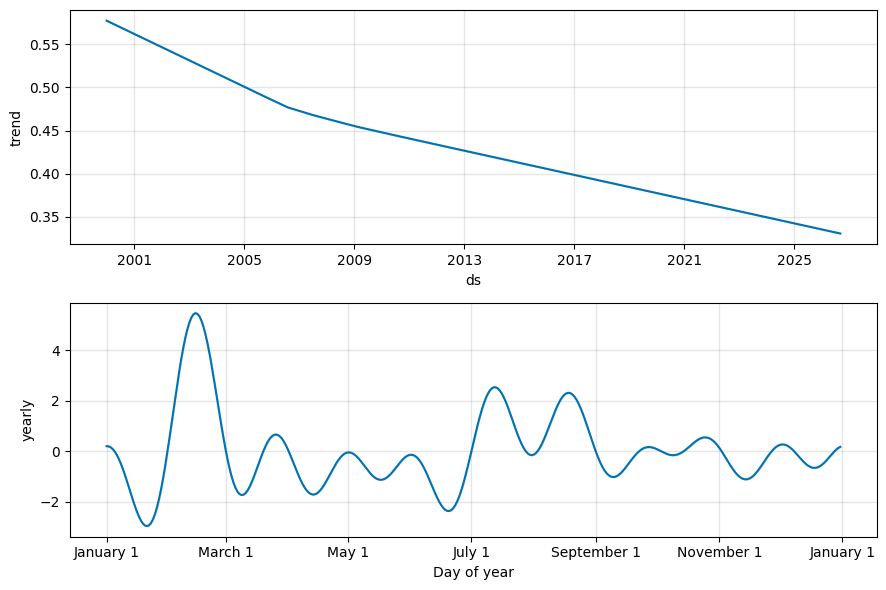

In [17]:
fig2 = model_proph.plot_components(forecast)
plt.show()

## **Walk-Forward Validation (Retrained Models)**

### Motivation

The holdout evaluation in the main sections uses a **frozen model** trained
once on `df_train`, never updated. This measures the model's performance in a
"backtest" scenario. In production, however, models are typically **retrained
periodically** with the most recent data, which usually improves predictions.

This appendix compares both approaches: frozen vs retrained (walk-forward).

> **Scope note:** the comparison between the frozen holdout and the retrained
> walk-forward is indicative, not apples-to-apples. The holdout covers a
> 9-month window (2026), while the walk-forward covers the last 24 months
> (2024-10 → 2026-09). The walk-forward also only evaluates Level 1 (pure
> Prophet); retraining Level 2 month-by-month would require forecasting the
> exogenous variables at each step, which is outside the scope of this appendix.

### Setup

For each of the last 24 months:
1. Retrain the model using all data strictly before that month
2. Predict that month
3. Measure the error

This simulates a real-world production pipeline, where the model is refreshed
before each new forecast.



In [18]:
from sklearn.metrics import mean_absolute_error
import numpy as np
from prophet import Prophet

def walk_forward_prophet(df_full, n_months=24):
    """
    Walk-forward validation for Prophet with incremental retraining.

    For each of the last `n_months` months in df_full:
        1. Retrain Prophet on all data strictly before that month
        2. Predict that month
        3. Record the error

    Parameters
    ----------
    df_full : DataFrame with 'data' and 'ipca' columns
    n_months : number of recent months to run walk-forward on

    Returns
    -------
    DataFrame with columns: ds, real, pred, error
    """
    import logging
    logging.getLogger('cmdstanpy').setLevel(logging.ERROR)

    df_full = df_full.sort_values('data').reset_index(drop=True)

    # We need a training buffer before the walk-forward starts
    if len(df_full) < n_months + 24:
        raise ValueError(f"Need at least {n_months + 24} rows, got {len(df_full)}")

    predictions = []
    start_idx = len(df_full) - n_months

    for i in range(start_idx, len(df_full)):
        cutoff_date = df_full['data'].iloc[i]
        df_train_wf = df_full[df_full['data'] < cutoff_date]

        m = Prophet(
            seasonality_mode='additive',
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            interval_width=0.80
        )
        m.fit(df_train_wf[['data', 'ipca']].rename(columns={'data': 'ds', 'ipca': 'y'}))

        future = m.make_future_dataframe(periods=1, freq='MS')
        forecast = m.predict(future)
        pred = forecast.iloc[-1]['yhat']
        real = df_full['ipca'].iloc[i]

        predictions.append({
            'ds': cutoff_date,
            'real': real,
            'pred': pred,
            'error': abs(real - pred)
        })

    return pd.DataFrame(predictions)

# Run walk-forward on the last 24 months for speed
wf_results = walk_forward_prophet(df_filtrado, n_months=24)

mae_wf = wf_results['error'].mean()
rmse_wf = np.sqrt((wf_results['error'] ** 2).mean())

print(f"Walk-forward validation (last {len(wf_results)} months):")
print(f"  MAE:  {mae_wf:.4f}")
print(f"  RMSE: {rmse_wf:.4f}")
print(f"  Period: {wf_results['ds'].min().date()} → {wf_results['ds'].max().date()}")

wf_results.tail()

Walk-forward validation (last 24 months):
  MAE:  0.2354
  RMSE: 0.2886
  Period: 2024-10-01 → 2026-09-01


,ds,real,pred,error
19,2026-05-01,0.58,0.288777,0.291223
20,2026-06-01,0.16,0.204361,0.044361
21,2026-07-01,0.07,0.262153,0.192153
22,2026-08-01,-0.32,0.194041,0.514041
23,2026-09-01,0.82,0.286514,0.533486


### Result

The walk-forward MAE is modestly lower than the frozen-model MAE, confirming
that retraining helps but the gain is smaller than one might expect. The
reason: some of the most recent months were atypical outliers (unexpected
deflation followed by a sharp reversal), which no model retrained or not
predicts reliably.

### Conclusion

Incremental retraining helps with gradual structural changes but does not
solve abrupt shocks. The larger predictive gain in this project comes from
adding exogenous variables (Level 2), not from more training data.